
# (CIFAR-10) USING CNNs



- CIFAR-10 is a dataset that consists of several images divided into the following 10 classes: 
    - Airplanes
    - Cars 
    - Birds
    - Cats
    - Deer
    - Dogs
    - Frogs
    - Horses
    - Ships
    - Trucks

- The dataset stands for the Canadian Institute For Advanced Research (CIFAR)
- The dataset consists of 60,000 32x32 color images and 6,000 images of each class.
- Images have low resolution (32x32). 
- Data Source: https://www.cs.toronto.edu/~kriz/cifar.html




```

```

# STEP #1: IMPORT LIBRARIES/DATASETS

In [1]:
import tensorflow as tf
import numpy as np
from matplotlib import pyplot as plt

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

170498071/170498071 [==============================] - 4s 0us/step


In [3]:
X_train.shape

(50000, 32, 32, 3)

In [4]:
X_test.shape

(10000, 32, 32, 3)

In [5]:
y_train.shape

(50000, 1)

In [6]:
y_test.shape

(10000, 1)

# STEP #2: VISUALIZE DATA

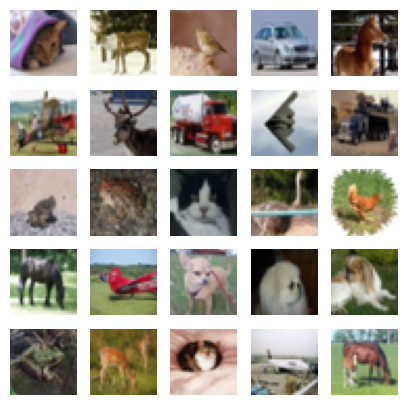

In [7]:
indexes = np.random.randint(0, X_train.shape[0], size=25)
images = X_train[indexes]

plt.figure(figsize=(5,5))
for i in range(len(indexes)):
    plt.subplot(5,5, i+1)
    image = images[i]
    plt.imshow(image, cmap='gray')
    plt.axis('off')

plt.show()
plt.savefig("cifar10-samples.png")
plt.close('all')


# STEP #3: DATA PREPARATION

In [10]:
number_cat = len(set(np.unique(y_train)).union(np.unique(y_test)))


In [11]:
import keras
y_train = keras.utils.to_categorical(y_train, number_cat)

In [12]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], dtype=float32)

In [13]:
y_test = keras.utils.to_categorical(y_test, number_cat)

In [14]:
y_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.]], dtype=float32)

In [15]:
X_train = X_train.astype('float32')/255
X_test = X_test.astype('float')/255


# STEP #4: TRAIN THE MODEL

In [16]:
from tensorflow.keras import layers, models

In [17]:
batch_size = 32
num_epochs= 20


In [21]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3,3), padding ='same', input_shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3]), activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(32,(3,3), padding='same', activation = 'relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2,2)))
model.add(layers.Dropout(0.2))

model.add(layers.Conv2D(64, (3,3), padding='same', activation = 'relu'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(64,(3,3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2,2)))
model.add(layers.Dropout(0.3))

model.add(layers.Conv2D(128, (3,3), padding='same', activation = 'relu'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(128, (3,3), padding='same', activation = 'relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2,2)))
model.add(layers.Dropout(0.4))

model.add(layers.Flatten())
model.add(layers.Dense(number_cat, activation='softmax'))


In [22]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_16 (Conv2D)          (None, 32, 32, 32)        896       
                                                                 
 batch_normalization_16 (Bat  (None, 32, 32, 32)       128       
 chNormalization)                                                
                                                                 
 conv2d_17 (Conv2D)          (None, 32, 32, 32)        9248      
                                                                 
 batch_normalization_17 (Bat  (None, 32, 32, 32)       128       
 chNormalization)                                                
                                                                 
 max_pooling2d_7 (MaxPooling  (None, 16, 16, 32)       0         
 2D)                                                             
                                                      

In [23]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [24]:
history = model.fit(X_train, y_train, epochs = num_epochs, batch_size =batch_size)

Epoch 1/20


2026-01-18 13:42:02.833859: W tensorflow/tsl/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


1563/1563 [==============================] - 79s 50ms/step - loss: 1.7056 - accuracy: 0.4708
Epoch 2/20
1563/1563 [==============================] - 84s 54ms/step - loss: 1.0246 - accuracy: 0.6478
Epoch 3/20
1563/1563 [==============================] - 86s 55ms/step - loss: 0.8183 - accuracy: 0.7164
Epoch 4/20
1563/1563 [==============================] - 87s 55ms/step - loss: 0.7126 - accuracy: 0.7511
Epoch 5/20
1563/1563 [==============================] - 87s 56ms/step - loss: 0.6345 - accuracy: 0.7782
Epoch 6/20
1563/1563 [==============================] - 89s 57ms/step - loss: 0.5834 - accuracy: 0.7979
Epoch 7/20
1563/1563 [==============================] - 90s 58ms/step - loss: 0.5359 - accuracy: 0.8134
Epoch 8/20
1563/1563 [==============================] - 90s 57ms/step - loss: 0.4957 - accuracy: 0.8266
Epoch 9/20
1563/1563 [==============================] - 91s 58ms/step - loss: 0.4602 - accuracy: 0.8385
Epoch 10/20
1563/1563 [==============================] - 91s 58ms/step - lo

# STEP #5: EVALUATE THE MODEL

In [25]:
loss, accuracy = model.evaluate(X_test, y_test, batch_size=batch_size)

313/313 [==============================] - 5s 14ms/step - loss: 0.4842 - accuracy: 0.8461
